# 05. Évaluation et ablation (phase 5)

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "results"
pd.set_option("display.width", 200)
print('Segmentation (25 patients) :')
seg = pd.read_csv(RESULTS / 'segmentation_scores.csv')
print(f'Dice moyen {seg.dice.mean():.3f}, IoU moyen {seg.iou.mean():.3f}, Dice min {seg.dice.min():.3f}')

Segmentation (25 patients) :
Dice moyen 0.974, IoU moyen 0.950, Dice min 0.930


## Comparaison des scénarios A, B et C (même jeu de test)

In [2]:
display(pd.read_csv(RESULTS / 'comparaison_scenarios.csv'))

,scenario,sensibilite,specificite,precision,f1,auc_roc,TP,FP,FN,TN,sens_a_1FP,sens_a_4FP,temps_s,donnees
0,A : morphologie seule,0.091,0.986,0.032,0.048,0.748,1,30,10,2187,0.053,0.053,0.10,aucune (règles)
1,B : morphologie + ML,0.091,0.999,0.250,0.133,0.842,1,3,10,2214,0.105,0.263,0.65,descripteurs (~dev)
2,C : morphologie + CNN 3D,0.818,0.646,0.011,0.022,0.866,9,784,2,1433,0.105,0.158,869.40,patchs 3D (~dev)


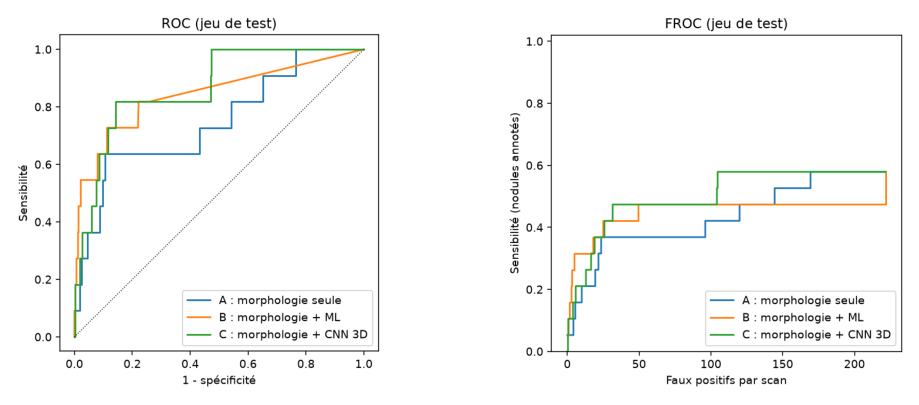

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, f in zip(ax, ('roc', 'froc')):
    a.imshow(mpimg.imread(RESULTS / 'figures' / f'{f}.png')); a.axis('off')
plt.show()

## Ablation de la chaîne morphologique

In [4]:
display(pd.read_csv(RESULTS / 'ablation_detection.csv'))

,variante,rappel_dev,fp_par_scan_dev,rappel_test,fp_par_scan_test,delta_rappel_test,delta_fp_test,etape_retiree
0,chaîne complète,0.88,215.6,0.579,221.7,0.000,0.0,NaN
1,sans ouverture (segmentation),0.88,222.1,0.632,230.9,0.053,9.2,ouverture (segmentation)
2,sans fermeture,0.68,169.6,0.368,192.7,-0.211,-29.0,fermeture + remplissage des trous
3,sans watershed,0.72,18.3,0.421,18.5,-0.158,-203.2,watershed
4,sans troncature,0.84,129.4,0.526,126.0,-0.053,-95.7,troncature en boule autour du pic
5,sans squelette,0.88,215.7,0.579,221.7,0.000,0.0,squelette + filtre de forme


In [5]:
display(pd.read_csv(RESULTS / 'ablation_descripteurs.csv'))

,variante,n_descripteurs,auc_test,sens_a_4FP,sens_a_10FP,delta_auc
0,tous les descripteurs,17,0.842,0.263,0.316,0.000
1,sans gradient,16,0.839,0.263,0.316,-0.003
2,sans squelette,13,0.894,0.316,0.316,0.052
3,sans descripteurs de forme,14,0.781,0.158,0.211,-0.061


In [6]:
chain = pd.read_csv(RESULTS / 'ablation_chaine.csv')
display(chain)
print(f"Étapes reposant sur la morphologie : {int(chain.morphologie.sum())}/{len(chain)} = {100*chain.morphologie.mean():.0f} %")

,etape,morphologie
0,rééchantillonnage + fenêtrage HU,False
1,seuillage du poumon,False
2,ouverture (segmentation),True
3,fermeture + remplissage des trous,True
4,seuillage des objets denses,False
5,transformée de distance + marqueurs,True
6,watershed,True
7,troncature en boule autour du pic,True
8,squelette + filtre de forme,True
9,gradient morphologique (descripteur),True


Étapes reposant sur la morphologie : 7/12 = 58 %


## Analyse d'erreurs

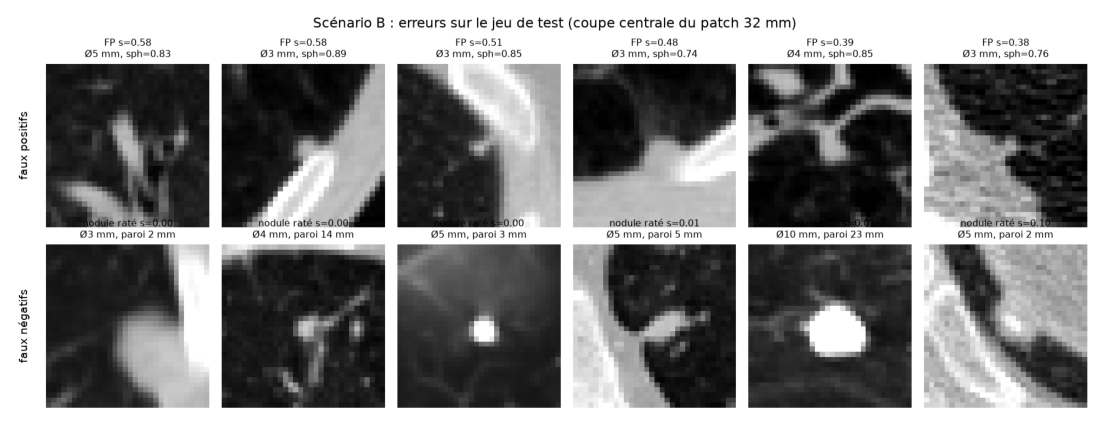

In [7]:
plt.figure(figsize=(14, 6)); plt.imshow(mpimg.imread(RESULTS / 'figures' / 'erreurs.png')); plt.axis('off'); plt.show()